# 01 - Baseline

Before building any model, establish the **floor**.

The simplest possible predictor: *tomorrow's close = today's close*.

Every real model must beat this. If it doesn't, the model is useless —
you'd be better off doing nothing.

This notebook:

1. Loads OHLCV and builds features
2. Splits train / test by time
3. Computes baseline RMSE, MAE, direction accuracy
4. Plots baseline vs actual
5. Saves results to `reports/predictions/baseline.json` for later comparison


## Setup

In [1]:
# --- setup --------------------------------------------------------
import sys, json
sys.path.insert(0, r"D:\Projects\done\eth_bot\eth_bot_v2")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from analysis.loader import load_ohlcv
from analysis.indicators import add_all

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (12, 4)

SEED = 42
np.random.seed(SEED)

## 1. Load data and build features

`make_features()` computes:

- returns over 1, 5, 20 days
- 20-day rolling volatility
- the standard indicators from `add_all()`
- `target` = next-day return (shifted up by 1 day)

The last row is dropped because we don't know tomorrow yet.

In [2]:
def make_features(horizon: int = 1) -> pd.DataFrame:
    df = load_ohlcv()
    df = add_all(df).copy()

    df["ret_1"]  = df["close"].pct_change(1)
    df["ret_5"]  = df["close"].pct_change(5)
    df["ret_20"] = df["close"].pct_change(20)
    df["vol_20"] = df["ret_1"].rolling(20).std()

    # target: next-day return
    df["target"] = df["close"].pct_change(horizon).shift(-horizon)

    return df.dropna()


df = make_features()
print(f"rows      : {len(df)}")
print(f"date range: {df.index.min().date()} -> {df.index.max().date()}")
print(f"columns   : {list(df.columns)}")
df[["close", "ret_1", "vol_20", "target"]].tail()

rows      : 1989
date range: 2021-04-22 -> 2026-10-01
columns   : ['open', 'high', 'low', 'close', 'volume', 'sma_50', 'sma_200', 'ema_12', 'ema_26', 'rsi_14', 'macd', 'macd_sig', 'macd_hist', 'atr_14', 'ret_1', 'ret_5', 'ret_20', 'vol_20', 'target']


,close,ret_1,vol_20,target
date,,,,
2026-09-27,2688.65,-0.002848,0.024805,0.000022
2026-09-28,2688.71,0.000022,0.024782,-0.003991
2026-09-29,2677.98,-0.003991,0.024724,0.002999
2026-09-30,2686.01,0.002999,0.024423,0.007599
2026-10-01,2706.42,0.007599,0.023603,-0.013978


## 2. Train / test split

Time-series data must be split **chronologically** — never shuffle.

- **Train**: everything except last 250 days
- **Test**: last 250 days

250 days ≈ 8 months — enough to see the baseline's behaviour across a
few different market regimes.

In [3]:
TEST_DAYS = 250

train = df.iloc[:-TEST_DAYS]
test  = df.iloc[-TEST_DAYS:]

print(f"train: {train.index.min().date()} -> {train.index.max().date()}  ({len(train)} rows)")
print(f"test : {test.index.min().date()}  -> {test.index.max().date()}   ({len(test)} rows)")

train: 2021-04-22 -> 2026-01-24  (1739 rows)
test : 2026-01-25  -> 2026-10-01   (250 rows)


## 3. Baseline prediction

The naive forecast: *tomorrow = today*.

In terms of the target (next-day return), the baseline prediction is
**0% return** — i.e. price stays flat.

In [4]:
# baseline prediction in price space
pred_price   = test["close"].shift(1)
actual_price = test["close"]
mask         = ~pred_price.isna()
pred_price   = pred_price[mask]
actual_price = actual_price[mask]

rmse_price = float(np.sqrt(((pred_price - actual_price) ** 2).mean()))
mae_price  = float((pred_price - actual_price).abs().mean())

print(f"PRICE SPACE")
print(f"  RMSE : {rmse_price:,.2f} USD")
print(f"  MAE  : {mae_price:,.2f} USD")

PRICE SPACE
  RMSE : 69.53 USD
  MAE  : 46.41 USD


## 4. Baseline in return space

Predicting **0% daily return** for every day. Compare to actual returns.

In [5]:
y_test = test["target"].values
pred_return = np.zeros_like(y_test)   # predict zero return

rmse_ret = float(np.sqrt(((pred_return - y_test) ** 2).mean()))
mae_ret  = float(np.abs(pred_return - y_test).mean())

# direction accuracy: did we get up/down right?
# baseline always predicts "flat" — count how often the day was up
dir_acc = float((y_test > 0).mean())

print(f"RETURN SPACE")
print(f"  RMSE         : {rmse_ret:.6f}")
print(f"  MAE          : {mae_ret:.6f}")
print(f"  dir accuracy : {dir_acc:.2%}   (baseline: always predict down)")

RETURN SPACE
  RMSE         : 0.032920
  MAE          : 0.021931
  dir accuracy : 52.00%   (baseline: always predict down)


## 5. Visualise: baseline vs actual

On top: prices. On bottom: cumulative return of baseline (flat) vs actual.

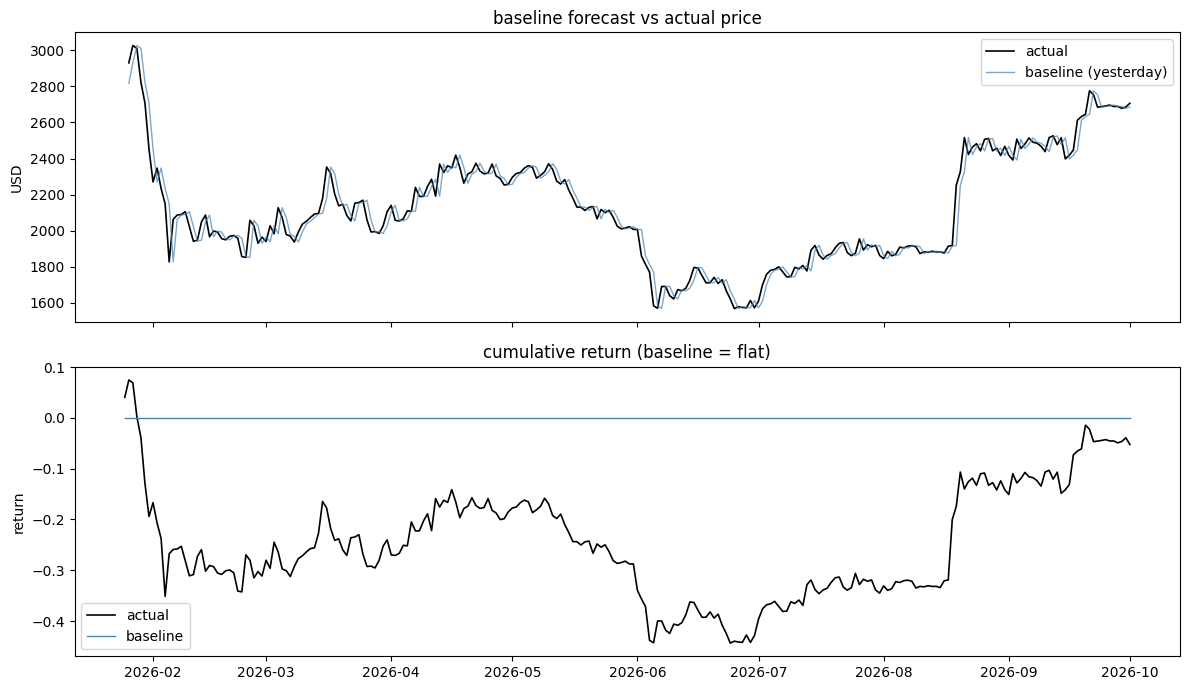

In [6]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# price panel
ax[0].plot(actual_price.index, actual_price.values, label="actual", color="black", lw=1.2)
ax[0].plot(pred_price.index,   pred_price.values,   label="baseline (yesterday)", color="steelblue", lw=1.0, alpha=0.7)
ax[0].set_title("baseline forecast vs actual price")
ax[0].set_ylabel("USD")
ax[0].legend()

# cumulative return panel
cum_actual   = (1 + test["target"]).cumprod() - 1
cum_baseline = pd.Series(0.0, index=test.index)
ax[1].plot(cum_actual.index,   cum_actual.values,   label="actual", color="black", lw=1.2)
ax[1].plot(cum_baseline.index, cum_baseline.values, label="baseline", color="steelblue", lw=1.0)
ax[1].set_title("cumulative return (baseline = flat)")
ax[1].set_ylabel("return")
ax[1].legend()

plt.tight_layout()
plt.show()

## 6. Error distribution

Histogram of the baseline's daily error.

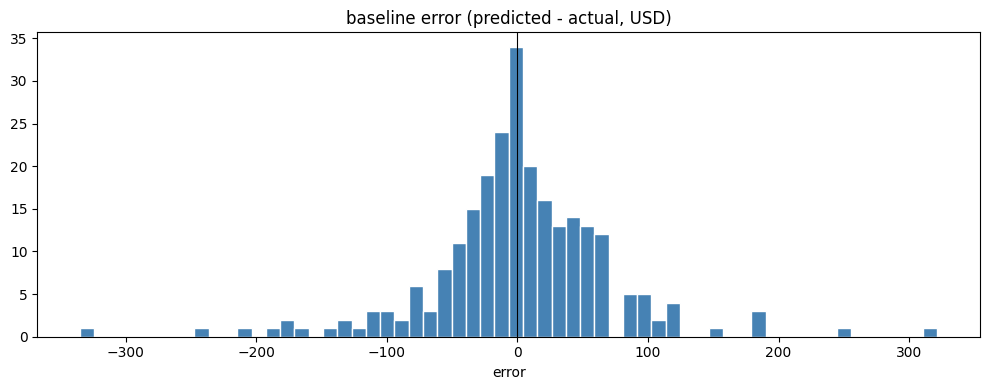

mean error : +0.44
std error  : 69.53
worst miss : -334.95
best miss  : 321.43


In [7]:
err = pred_price.values - actual_price.values

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(err, bins=60, color="steelblue", edgecolor="white")
ax.axvline(0, color="black", lw=0.8)
ax.set_title("baseline error (predicted - actual, USD)")
ax.set_xlabel("error")
plt.tight_layout()
plt.show()

print(f"mean error : {err.mean():+.2f}")
print(f"std error  : {err.std():.2f}")
print(f"worst miss : {err.min():.2f}")
print(f"best miss  : {err.max():.2f}")

## 7. Save results

Write the baseline numbers to `reports/predictions/baseline.json`
so later notebooks can compare against it.

In [8]:
OUT = Path(r"D:\Projects\done\eth_bot\eth_bot_v2") / "reports" / "predictions"
OUT.mkdir(parents=True, exist_ok=True)

results = {
    "model":      "baseline (tomorrow = today)",
    "test_days":  int(len(test)),
    "test_start": str(test.index.min().date()),
    "test_end":   str(test.index.max().date()),
    "price": {
        "rmse": rmse_price,
        "mae":  mae_price,
    },
    "return": {
        "rmse":         rmse_ret,
        "mae":          mae_ret,
        "dir_accuracy": dir_acc,
    },
}

path = OUT / "baseline.json"
path.write_text(json.dumps(results, indent=2), encoding="utf-8")
print(f"wrote {path}")
print(json.dumps(results, indent=2))

wrote D:\Projects\done\eth_bot\eth_bot_v2\reports\predictions\baseline.json
{
  "model": "baseline (tomorrow = today)",
  "test_days": 250,
  "test_start": "2026-01-25",
  "test_end": "2026-10-01",
  "price": {
    "rmse": 69.52714308312406,
    "mae": 46.41265060240964
  },
  "return": {
    "rmse": 0.03292027745197181,
    "mae": 0.021930686541874637,
    "dir_accuracy": 0.52
  }
}


## Next steps

The baseline is now on disk. Every model in the next notebooks will be
compared to it.

- **02_linear_regression.ipynb** — can a linear model beat this?
- **03_tree_models.ipynb** — do tree models improve on linear?
- **05_walkforward.ipynb** — walk-forward evaluation (the honest one)

**Golden rule**: if your fancy model's RMSE is not lower than the
baseline's, your model learned nothing. Delete it and try again.
